In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("./santander_train.csv")
df.head()

,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,...,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38,TARGET
0,1,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,39205.170000,0
1,3,2,34,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,49278.030000,0
2,4,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,67333.770000,0
3,8,2,37,0.0,195.0,195.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,64007.970000,0
4,10,2,39,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117310.979016,0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76020 entries, 0 to 76019
Columns: 371 entries, ID to TARGET
dtypes: float64(111), int64(260)
memory usage: 215.2 MB


In [10]:
df["TARGET"].value_counts()

0    73012
1     3008
Name: TARGET, dtype: int64

In [11]:
df.describe()

,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,...,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38,TARGET
count,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,...,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,7.602000e+04,76020.000000
mean,75964.050723,-1523.199277,33.212865,86.208265,72.363067,119.529632,3.559130,6.472698,0.412946,0.567352,...,7.935824,1.365146,12.215580,8.784074,31.505324,1.858575,76.026165,56.614351,1.172358e+05,0.039569
std,43781.947379,39033.462364,12.956486,1614.757313,339.315831,546.266294,93.155749,153.737066,30.604864,36.513513,...,455.887218,113.959637,783.207399,538.439211,2013.125393,147.786584,4040.337842,2852.579397,1.826646e+05,0.194945
min,1.000000,-999999.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.163750e+03,0.000000
25%,38104.750000,2.000000,23.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.787061e+04,0.000000
50%,76043.000000,2.000000,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.064092e+05,0.000000
75%,113748.750000,2.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.187563e+05,0.000000
max,151838.000000,238.000000,105.000000,210000.000000,12888.030000,21024.810000,8237.820000,11073.570000,6600.000000,6600.000000,...,50003.880000,20385.720000,138831.630000,91778.730000,438329.220000,24650.010000,681462.900000,397884.300000,2.203474e+07,1.000000


In [12]:
df["var3"].value_counts()

 2         74165
 8           138
-999999      116
 9           110
 3           108
           ...  
 231           1
 188           1
 168           1
 135           1
 87            1
Name: var3, Length: 208, dtype: int64

In [13]:
df["var3"].replace(-999999, 2, inplace = True)
df.drop("ID", axis = 1, inplace = True)

X_features = df.iloc[:, :-1]
y_label = df.iloc[:, -1]
X_features.shape

(76020, 369)

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_features, y_label,
                                test_size = 0.2, random_state = 0, stratify = y_label)

train_cnt = y_train.count()
test_cnt = y_test.count()

print(y_train.value_counts() / train_cnt)
print(y_test.value_counts() / test_cnt)

0    0.960438
1    0.039562
Name: TARGET, dtype: float64
0    0.960405
1    0.039595
Name: TARGET, dtype: float64


In [17]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train,
                        test_size = 0.3, random_state = 0)

In [19]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

xgb_clf = XGBClassifier(n_estimators = 500, learning_rate = 0.05,
                        random_state = 156)
xgb_clf.fit(X_tr, y_tr, early_stopping_rounds = 100, eval_metric = "auc",
            eval_set = [(X_tr, y_tr), (X_val, y_val)])

xgb_auc = roc_auc_score(y_test, xgb_clf.predict_proba(X_test)[:, 1])
print(xgb_auc)

[0]	validation_0-auc:0.83155	validation_1-auc:0.80088
[1]	validation_0-auc:0.83330	validation_1-auc:0.80089


/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


[2]	validation_0-auc:0.83749	validation_1-auc:0.80303
[3]	validation_0-auc:0.83661	validation_1-auc:0.80251
[4]	validation_0-auc:0.83739	validation_1-auc:0.80252
[5]	validation_0-auc:0.83841	validation_1-auc:0.80237
[6]	validation_0-auc:0.84131	validation_1-auc:0.80673
[7]	validation_0-auc:0.84135	validation_1-auc:0.80660
[8]	validation_0-auc:0.84304	validation_1-auc:0.80861
[9]	validation_0-auc:0.84550	validation_1-auc:0.81139
[10]	validation_0-auc:0.84620	validation_1-auc:0.81104
[11]	validation_0-auc:0.84641	validation_1-auc:0.81080
[12]	validation_0-auc:0.84760	validation_1-auc:0.81181
[13]	validation_0-auc:0.84804	validation_1-auc:0.81205
[14]	validation_0-auc:0.84865	validation_1-auc:0.81232
[15]	validation_0-auc:0.84912	validation_1-auc:0.81239
[16]	validation_0-auc:0.85052	validation_1-auc:0.81365
[17]	validation_0-auc:0.85165	validation_1-auc:0.81489
[18]	validation_0-auc:0.85204	validation_1-auc:0.81510
[19]	validation_0-auc:0.85234	validation_1-auc:0.81529
[20]	validation_0-

In [20]:
from hyperopt import hp

xgb_search_space = {"max_depth": hp.quniform("max_depth", 5, 15, 1),
                    "min_child_weight": hp.quniform("min_child_weight", 1, 6, 1),
                    "colsample_bytree": hp.uniform("colsample_bytree", 0.5, 0.95),
                    "learning_rate": hp.uniform("learning_rate", 0.01, 0.2)
                    }

In [22]:
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

def objective_func(search_space):
    xgb_clf = XGBClassifier(n_estimators = 100,
            max_depth = int(search_space["max_depth"]),
            min_child_weight = int(search_space["min_child_weight"]),
            colsample_bytree = search_space["colsample_bytree"],
            learning_rate = search_space["learning_rate"]
            )
    roc_auc = []

    kf = KFold(n_splits = 3)
    for tr_index, val_index in kf.split(X_train):
        X_tr, y_tr = X_train.iloc[tr_index], y_train.iloc[tr_index]
        X_val, y_val = X_train.iloc[val_index], y_train.iloc[val_index]
        xgb_clf.fit(X_tr, y_tr, early_stopping_rounds = 30,
                    eval_metric = "auc",
                    eval_set = [(X_tr, y_tr), (X_val, y_val)])
        score = roc_auc_score(y_val, xgb_clf.predict_proba(X_val)[:, 1])
        roc_auc.append(score)

    return -1 * np.mean(roc_auc)


In [23]:
from hyperopt import fmin, tpe, Trials

trials = Trials()

best = fmin(fn = objective_func, space = xgb_search_space,
            algo = tpe.suggest, max_evals = 50, trials = trials,
            rstate = np.random.default_rng(seed = 30))
print(best)

  0%|          | 0/50 [00:00<?, ?trial/s, best loss=?]

/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[0]	validation_0-auc:0.74406	validation_1-auc:0.73158 
[1]	validation_0-auc:0.76447	validation_1-auc:0.74466 
[2]	validation_0-auc:0.82588	validation_1-auc:0.80978 
[3]	validation_0-auc:0.83834	validation_1-auc:0.82307 
[4]	validation_0-auc:0.84512	validation_1-auc:0.82836 
[5]	validation_0-auc:0.84769	validation_1-auc:0.82913 
[6]	validation_0-auc:0.84730	validation_1-auc:0.82758 
[7]	validation_0-auc:0.84917	validation_1-auc:0.82819 
[8]	validation_0-auc:0.84825	validation_1-auc:0.82592 
[9]	validation_0-auc:0.84647	validation_1-auc:0.82309 
[10]	validation_0-auc:0.85113	validation_1-auc:0.82769
[11]	validation_0-auc:0.85360	validation_1-auc:0.82955
[12]	validation_0-auc:0.85599	validation_1-auc:0.83121
[13]	validation_0-auc:0.85699	validation_1-auc:0.83067
[14]	validation_0-auc:0.85877	validation_1-auc:0.83234
[15]	validation_0-auc:0.86018	validation_1-auc:0.83440
[16]	validation_0-auc:0.86132	validation_1-auc:0.83518
[17]	validation_0-auc:0.86328	validation_1-auc:0.83650
[18]	valid

/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[2]	validation_0-auc:0.82696	validation_1-auc:0.80249 
[3]	validation_0-auc:0.84235	validation_1-auc:0.81650 
[4]	validation_0-auc:0.84716	validation_1-auc:0.82048 
[5]	validation_0-auc:0.84911	validation_1-auc:0.82146 
[6]	validation_0-auc:0.85021	validation_1-auc:0.82069 
[7]	validation_0-auc:0.85192	validation_1-auc:0.82227 
[8]	validation_0-auc:0.85168	validation_1-auc:0.81905 
[9]	validation_0-auc:0.85089	validation_1-auc:0.81775 
[10]	validation_0-auc:0.85445	validation_1-auc:0.82023
[11]	validation_0-auc:0.85712	validation_1-auc:0.82337
[12]	validation_0-auc:0.85826	validation_1-auc:0.82434
[13]	validation_0-auc:0.85666	validation_1-auc:0.82329
[14]	validation_0-auc:0.85853	validation_1-auc:0.82468
[15]	validation_0-auc:0.85965	validation_1-auc:0.82542
[16]	validation_0-auc:0.86149	validation_1-auc:0.82651
[17]	validation_0-auc:0.86255	validation_1-auc:0.82686
[18]	validation_0-auc:0.86401	validation_1-auc:0.82829
[19]	validation_0-auc:0.86447	validation_1-auc:0.82912
[20]	valid

...

[1]	validation_0-auc:0.77219	validation_1-auc:0.74139                             
[2]	validation_0-auc:0.84590	validation_1-auc:0.80741                             
[3]	validation_0-auc:0.85962	validation_1-auc:0.81711                             
[4]	validation_0-auc:0.86792	validation_1-auc:0.82226                             
[5]	validation_0-auc:0.87287	validation_1-auc:0.82549                             
[6]	validation_0-auc:0.87669	validation_1-auc:0.82340                             
[7]	validation_0-auc:0.87980	validation_1-auc:0.82609                             
[8]	validation_0-auc:0.88434	validation_1-auc:0.82442                             
[9]	validation_0-auc:0.88896	validation_1-auc:0.82645                             
[10]	validation_0-auc:0.89433	validation_1-auc:0.82781                            
[11]	validation_0-auc:0.89570	validation_1-auc:0.82917                            
[12]	validation_0-auc:0.89819	validation_1-auc:0.82997                            
[13]

/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[1]	validation_0-auc:0.76534	validation_1-auc:0.73967                             
[2]	validation_0-auc:0.83954	validation_1-auc:0.80362                             
[3]	validation_0-auc:0.85588	validation_1-auc:0.81195                             
[4]	validation_0-auc:0.86255	validation_1-auc:0.81631                             
[5]	validation_0-auc:0.86969	validation_1-auc:0.81928                             
[6]	validation_0-auc:0.87270	validation_1-auc:0.81798                             
[7]	validation_0-auc:0.87871	validation_1-auc:0.82011                             
[8]	validation_0-auc:0.88173	validation_1-auc:0.81700                             
[9]	validation_0-auc:0.89035	validation_1-auc:0.81852                             
[10]	validation_0-auc:0.89415	validation_1-auc:0.81947                            
[11]	validation_0-auc:0.89704	validation_1-auc:0.82195                            
[12]	validation_0-auc:0.90161	validation_1-auc:0.82412                            
[13]

/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[1]	validation_0-auc:0.77481	validation_1-auc:0.75526                             
[2]	validation_0-auc:0.84113	validation_1-auc:0.81116                             
[3]	validation_0-auc:0.85134	validation_1-auc:0.81575                             
[4]	validation_0-auc:0.85933	validation_1-auc:0.82222                             
[5]	validation_0-auc:0.86581	validation_1-auc:0.82552                             
[6]	validation_0-auc:0.86711	validation_1-auc:0.82289                             
[7]	validation_0-auc:0.87457	validation_1-auc:0.82493                             
[8]	validation_0-auc:0.87817	validation_1-auc:0.82289                             
[9]	validation_0-auc:0.88244	validation_1-auc:0.82836                             
[10]	validation_0-auc:0.88735	validation_1-auc:0.82954                            
[11]	validation_0-auc:0.89042	validation_1-auc:0.83123                            
[12]	validation_0-auc:0.89406	validation_1-auc:0.83175                            
[13]

In [24]:
xgb_clf = XGBClassifier(n_estimators = 500,
            learning_rate = round(best["learning_rate"], 5),
            max_depth = int(best["max_depth"]),
            min_child_weight = int(best["min_child_weight"]),
            colsample_bytree = round(best["colsample_bytree"], 5)
            )

xgb_clf.fit(X_tr, y_tr, early_stopping_rounds = 100,
            eval_metric = "auc", eval_set = [(X_tr, y_tr), (X_val, y_val)])

xgb_auc_score = roc_auc_score(y_test, xgb_clf.predict_proba(X_test)[:, 1])
print(xgb_auc_score)

[0]	validation_0-auc:0.72089	validation_1-auc:0.71464


/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/xgboost/sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


[1]	validation_0-auc:0.76009	validation_1-auc:0.74420
[2]	validation_0-auc:0.82264	validation_1-auc:0.80864
[3]	validation_0-auc:0.83137	validation_1-auc:0.81727
[4]	validation_0-auc:0.83849	validation_1-auc:0.82640
[5]	validation_0-auc:0.84055	validation_1-auc:0.82895
[6]	validation_0-auc:0.84038	validation_1-auc:0.82576
[7]	validation_0-auc:0.84419	validation_1-auc:0.83019
[8]	validation_0-auc:0.84377	validation_1-auc:0.82721
[9]	validation_0-auc:0.84080	validation_1-auc:0.82373
[10]	validation_0-auc:0.84531	validation_1-auc:0.82859
[11]	validation_0-auc:0.84796	validation_1-auc:0.83084
[12]	validation_0-auc:0.85120	validation_1-auc:0.83420
[13]	validation_0-auc:0.84993	validation_1-auc:0.83211
[14]	validation_0-auc:0.85046	validation_1-auc:0.83134
[15]	validation_0-auc:0.85336	validation_1-auc:0.83494
[16]	validation_0-auc:0.85246	validation_1-auc:0.83356
[17]	validation_0-auc:0.85467	validation_1-auc:0.83596
[18]	validation_0-auc:0.85737	validation_1-auc:0.83742
[19]	validation_0-a

<AxesSubplot: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

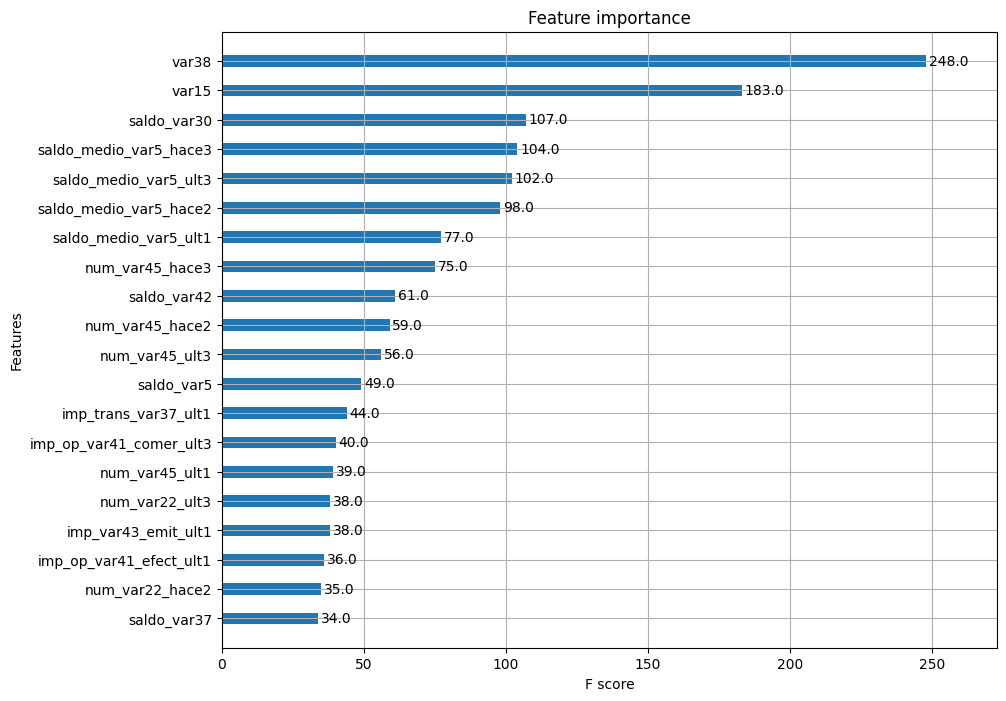

In [25]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize = (10, 8))
plot_importance(xgb_clf, ax = ax, max_num_features = 20, height = 0.4)